In [1]:
import numpy as np
import random
from tqdm import *
from itertools import cycle, count
import gym
from RLHelper import *  # 헬퍼 모듈

## 몬테카를로 예측 알고리즘

In [16]:
def mc_prediction(pi, env, gamma=1.0, init_alpha=0.5, min_alpha=0.01, alpha_decay_ratio=0.5, 
                  n_episodes=500, max_steps=200, first_visit=True):
    """
    주어진 정책 하에서 가치 함수를 추정하기 위한 몬테카를로 예측.
    
    매개변수:
    pi: 정책
    env: 환경
    gamma: 할인율
    init_alpha: 초기 학습률
    min_alpha: 최소 학습률
    alpha_decay_ratio: 학습률이 감소되는 비율
    n_episodes: 에피소드 수
    max_steps: 에피소드 당 최대 스텝 수
    first_visit: 첫 방문 MC(True) 또는 모든 방문 MC(False) 여부
    
    반환값:
    V: 추정된 가치 함수
    V_track: 에피소드 동안 추적된 가치 함수
    targets: 각 상태에 대해 관찰된 반환 값의 리스트
    """
    nS = env.observation_space.n  # 상태 수
    # 각 스텝에 대한 할인율 미리 계산
    discounts = np.logspace(0, max_steps, num=max_steps, base=gamma, endpoint=False)
    # 감소하는 학습률 계산
    alphas = decay_schedule(init_alpha, min_alpha, alpha_decay_ratio, n_episodes)
    V = np.zeros(nS, dtype=np.float64)  # 가치 함수 초기화
    V_track = np.zeros((n_episodes, nS), dtype=np.float64)  # 에피소드 동안 가치 함수 추적
    targets = {state: [] for state in range(nS)}  # 각 상태에 대한 타겟 초기화

    for e in tqdm(range(n_episodes), leave=False):
        # 전체 경로 생성
        trajectory = generate_trajectory(pi, env, max_steps)
        visited = np.zeros(nS, dtype=bool)  # 첫 방문 MC를 위한 방문된 상태 추적

        for t, (state, _, reward, _, _) in enumerate(trajectory):
            if visited[state] and first_visit:
                continue
            visited[state] = True  # 상태를 방문된 것으로 표시
            n_steps = len(trajectory[t:])  # 에피소드 끝까지의 스텝 수
            # 반환 값 계산
            G = np.sum(discounts[:n_steps] * trajectory[t:, 2])
            targets[state].append(G)
            # MC 오류
            mc_error = G - V[state]
            # 가치 함수 갱신
            V[state] += alphas[e] * mc_error
        V_track[e] = V

    return V.copy(), V_track, targets

def decay_schedule(init_value, min_value, decay_ratio, max_steps, log_start=-2, log_base=10):
    """
    학습률에 대한 감소 일정을 계산.
    
    매개변수:
    init_value: 초기 값
    min_value: 최소 값
    decay_ratio: 감소되는 비율
    max_steps: 총 스텝 수
    log_start: 로그 스페이스의 시작 값
    log_base: 로그 스페이스의 기본 값
    
    반환값:
    values: 감소된 값들
    """
    decay_steps = int(max_steps * decay_ratio)
    rem_steps = max_steps - decay_steps
    values = np.logspace(log_start, 0, decay_steps, base=log_base, endpoint=True)[::-1]
    values = (values - values.min()) / (values.max() - values.min())
    values = (init_value - min_value) * values + min_value
    values = np.pad(values, (0, rem_steps), 'edge')
    return values

def generate_trajectory(pi, env, max_steps=200):
    """
    주어진 환경에서 정책을 따라 경로를 생성.
    
    매개변수:
    pi: 정책
    env: 환경
    max_steps: 에피소드 당 최대 스텝 수
    
    반환값:
    trajectory: 경험 튜플 리스트
    """
    trajectory = []
    state = env.reset()[0]
    for t in count():
        action = pi(state)
        next_state, reward, done, _, _ = env.step(action)
        experience = (state, action, reward, next_state, done)
        trajectory.append(experience)
        if done or t >= max_steps - 1:
            break
        state = next_state
    return np.array(trajectory, object)


## 첫 방문 몬테카를로 예측 (First Visit Monte Carlo Prediction)

In [17]:
 ## 프로즌 레이크 환경 생성
env = gym.make('FrozenLake-v1')

 # 파라미터초기화
init_state= env.reset()
 goal_state= 15
 gamma = 0.99
 n_episodes= 2500
 P = env.env.P # 상태

All seeds: 100%|█████████████████████████████████████████████████████████████████████████| 5/5 [00:15<00:00,  3.17s/it]


>> 첫방문몬테카를로예측(FVMC)
상태-가치함수:
| 00  0.551 | 01  0.498 | 02  0.468 | 03  0.451 |
| 04  0.568 |           | 06  0.359 |           |
| 08  0.602 | 09  0.655 | 10  0.625 |           |
|           | 13  0.754 | 14   0.87 |           |

State-value function errors:
| 00  0.009 | 01 -0.001 | 02 -0.003 | 03 -0.006 |
| 04  0.009 |           | 06  0.001 |           |
| 08   0.01 | 09  0.012 | 10  0.009 |           |
|           | 13  0.012 | 14  0.007 |           |
RMSE: 0.0067


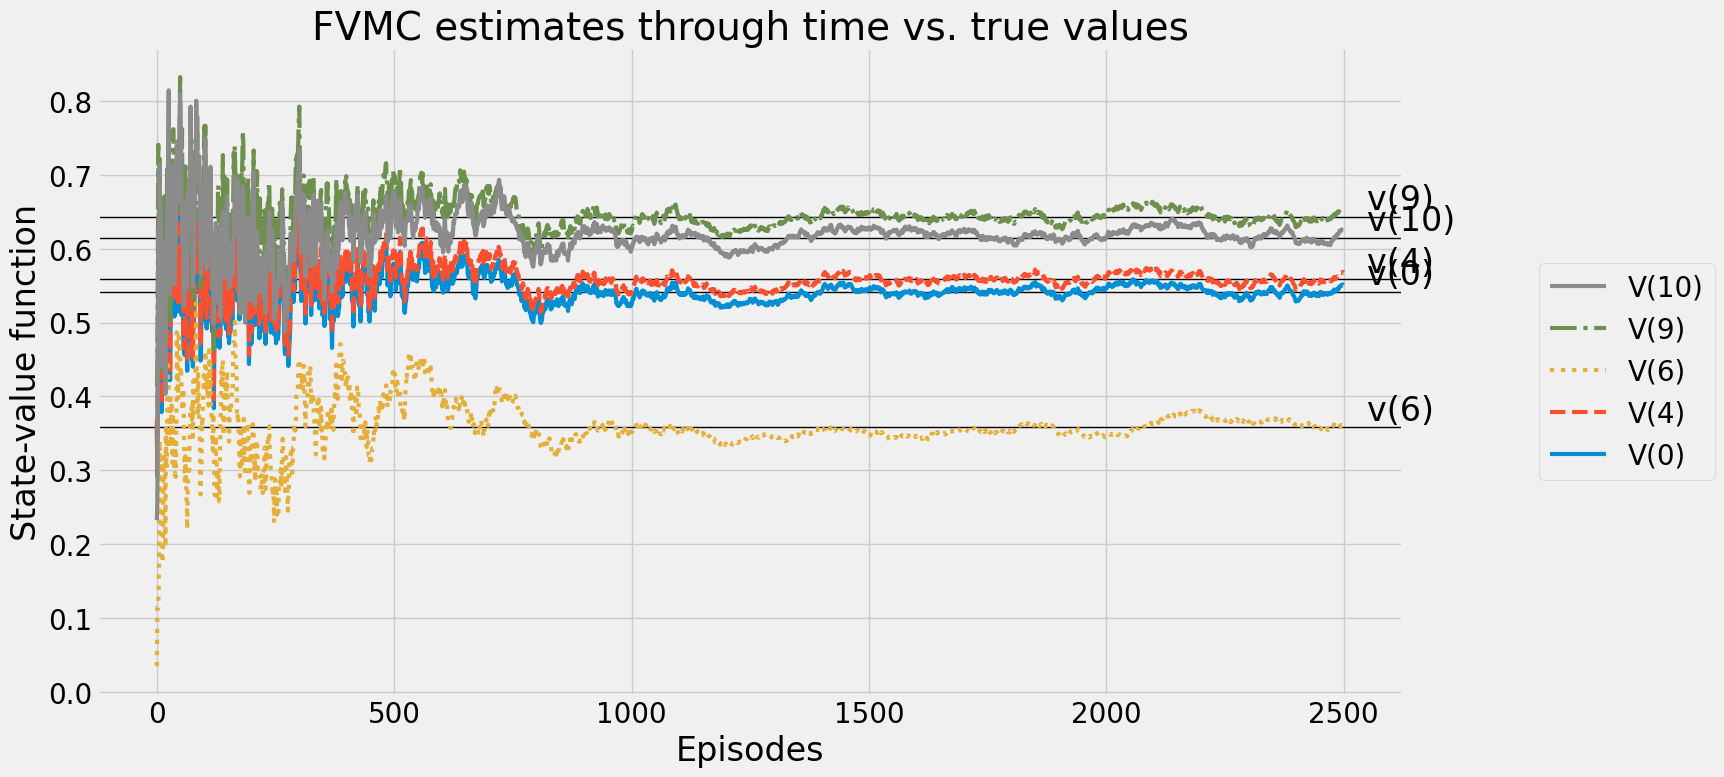

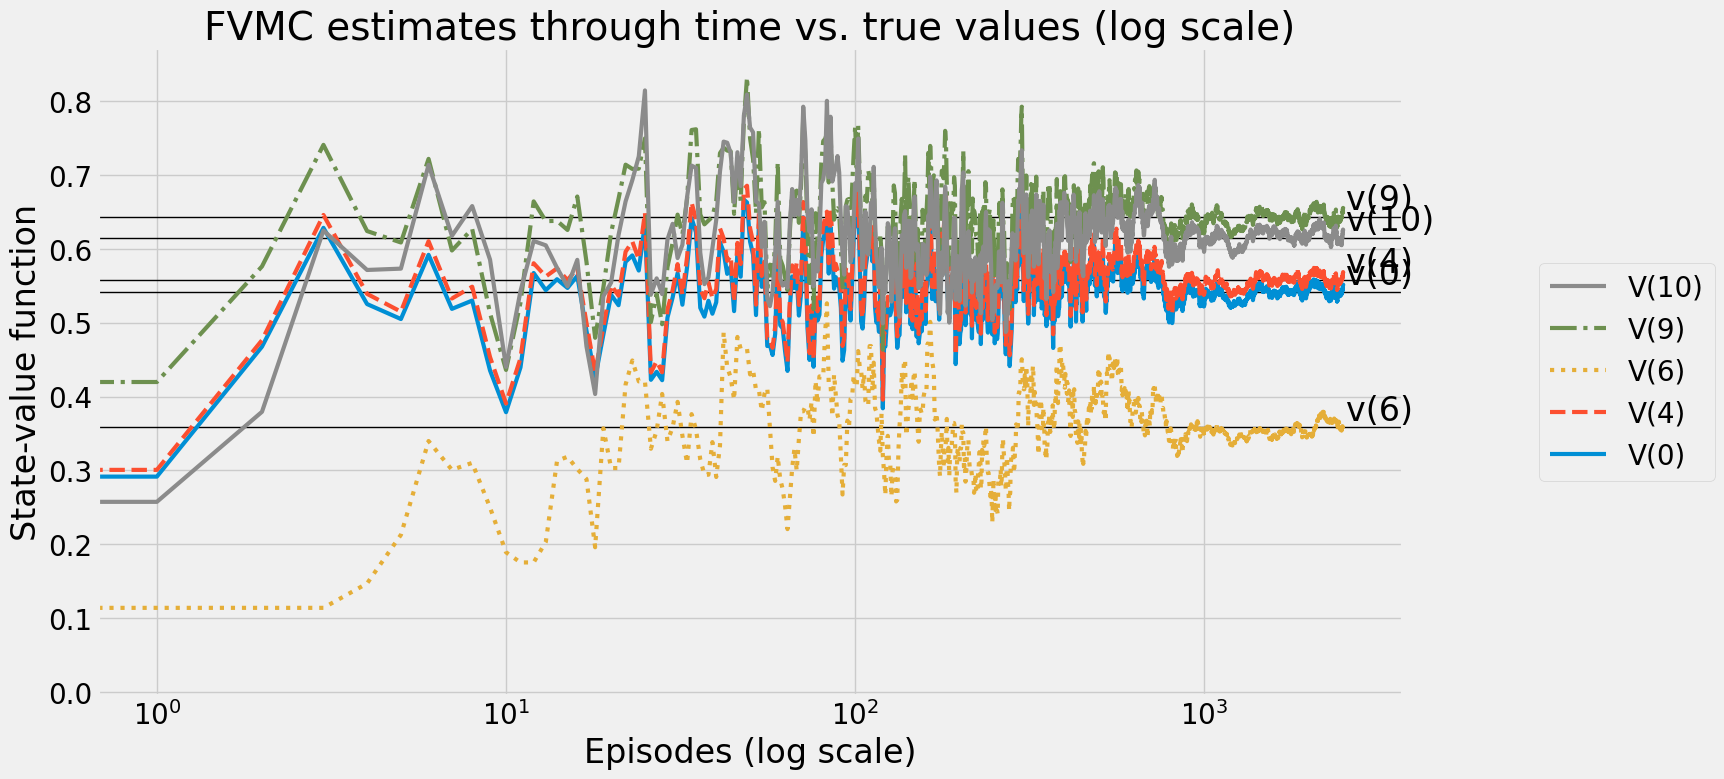

In [18]:
# 각기 다른 시드값으로 5번 수행 후의 상태 - 가치함수 평균 값
SEEDS = (12, 34, 56, 78, 90)       
V_fvmcs, V_track_fvmcs= [], []           # 5번 수행 상태-가치 함수 임시 저장


# 5개 시드에 대해 FVMC 반복 수행
for seed in tqdm(SEEDS, desc='All seeds', leave=True):
    random.seed(seed); np.random.seed(seed); env.reset(seed=seed)
    # 몬테카를로 예측 수행
    V_fvmc, V_track_fvmc, targets_fvmc= mc_prediction(pi, env, gamma=gamma, n_episodes=n_episodes)
    
    # 상태-가치함수 저장
    V_fvmcs.append(V_fvmc) ; V_track_fvmcs.append(V_track_fvmc)


# 5개의 상태 - 가치함수 평균 값 계산
V_fvmc, V_track_fvmc= np.mean(V_fvmcs, axis=0), np.mean(V_track_fvmcs, axis=0)
del V_fvmcs; del V_track_fvmcs # 임시 변수 제거
# 가치함수, 가치함수에러, 평균 제곱근 오차 출력
print(">> 첫방문몬테카를로예측(FVMC)")
print_state_value_function(V_fvmc, P)
print()
print_state_value_function(V_fvmc-V_true, P, title='State-value function errors:')
print('RMSE:', rmse(V_fvmc, V_true))
# 에피소드 진행에 따른 FVMC 상태 -가치함수 값 추정 그래프, 5개 상태 임의의 선택
# 에피소드가 진행함에 따라 참의 값으로 수렴

plot_value_function('FVMC estimates through time vs. true values', V_track_fvmc, V_true, log=False)
# x축을 로그 스케일로 변환한 그래프
plot_value_function('FVMC estimates through time vs. true values (log scale)', V_track_fvmc, V_true, log=True)


In [3]:
## 샘플정책생성
LEFT, DOWN, RIGHT, UP = range(4)
pi = lambda s: {
    0:LEFT, 1:UP, 2:UP, 3:UP,
    4:LEFT, 5:LEFT, 6:LEFT, 7:LEFT,
    8:UP, 9:DOWN, 10:LEFT, 11:LEFT,
    12:LEFT, 13:RIGHT, 14:DOWN, 15:LEFT
    }[s]
## 참상태-가치함수계산: 동적 계획법의 정책 평가
# 동적 계획법의 정책 평가 수행

V_true= policy_evaluation(pi, P, gamma=gamma)
 # 가치함수, 정책, 성공확률출력
print(">> 참상태-가치함수: 동적계획법정책평가")
print_state_value_function(V_true, P)
print()
print_policy(pi, P)
print('성공확률{:.2f}%. 평균리턴값{:.4f}.'.format(
    probability_success(env, pi, goal_state=goal_state), 
    mean_return(env, gamma, pi)))

>> 참상태-가치함수: 동적계획법정책평가
상태-가치함수:
| 00  0.542 | 01  0.499 | 02  0.471 | 03  0.457 |
| 04  0.558 |           | 06  0.358 |           |
| 08  0.592 | 09  0.643 | 10  0.615 |           |
|           | 13  0.742 | 14  0.863 |           |

정책:
| 00      < | 01      ^ | 02      ^ | 03      ^ |
| 04      < |           | 06      < |           |
| 08      ^ | 09      v | 10      < |           |
|           | 13      > | 14      v |           |
성공확률1.00%. 평균리턴값0.7700.


C:\Users\kuroc\anaconda3\Lib\site-packages\gym\utils\passive_env_checker.py:233: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):
